# evaluation and transfer: Methods and evidence

**Level:** 2 **Prerequisites:** Evaluation, transfer and limits level 1 **Reading time:** 25 minutes

**Question:** Do fresh M01 and M04 runs reproduce the task outcomes on the same C01 conditions?

## Objectives

This lesson investigates the question: Do fresh M01 and M04 runs reproduce the task outcomes on the same C01 conditions?

## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata;

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
The notebook reads committed product artifacts. Owner: Neuraxis. Repository: https://github.com/fsantibanezleal/CAOS_Neuraxis. License: Apache-2.0. The JSON is a first-party, frozen experiment artifact; no external benchmark data are redistributed in this notebook;

This notebook reads `data/derived/index.json` and the listed trace artifacts. The method run uses an isolated Reflexmesh case workspace; For learned methods, fetch the exact public release assets with `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder; The release manifest verifies asset hashes. Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model;

Artifacts for this lesson:

- `data/derived/index.json` - `data/derived/benchmark-adequacy.json` - `data/derived/research.json` - `data/derived/semantic-transfer/index.json` - `data/derived/semantic-transfer/report.json` - `data/derived/episodes/M01-C01-nominal-40000; - `data/derived/episodes/M04-C01-nominal-40000; - `data/derived/episodes/M09-C01-nominal-40000; - `data/derived/episodes/M12-C01-nominal-40000;json`

## Method

The core suite contains 14,400 indexed episodes, but the ten seed labels do not create ten independent task designs when outcomes repeat exactly. Hashing verifies bytes and identities; it does not make a task representative. The semantic-transfer lane changes operation names and compositions, while structural transfer and matched routing are separate evidence lanes with their own lineage. Keep the denominators separate and inspect failures by family before averaging. The published data show a saturated core in which five methods solve all 1,200 outcomes, and a small semantic sample where M04 outperforms M12. This weakens a superiority claim rather than demonstrating that any one method is universally best. In the reproducibility check for evaluation and transfer on C01, the episode index is an audit surface, not the inferential unit: In the reproducibility check for evaluation and transfer on C01, task family, variant and seed determine which outcomes are independent and which comparisons share a designed environment. For the matched evaluation and transfer rerun on C01, report every attempted episode in the denominator, retain failures and distinguish core cases from held-out transfer compositions before calculating success or confidence intervals. For this level, keep core, transfer and ablation results in separate tables, and state the number of families, variants, seeds and failed episodes behind every aggregate.

### evaluation and transfer · level 2 — Verify the audit and each trace's bytes before interpreting outcomes.

In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M01", "M04", "M09", "M12"]
trace_methods = ["M01", "M04", "M09", "M12"]
sample_case = "C01"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 4


### evaluation and transfer · level 2 — Execute the released policies and compare the run

### evaluation and transfer · level 2 — Compare the full sequence, not only the first action

### evaluation and transfer · L2 — Build the first executable policy

In level 2, construct policy M01 for evaluation and transfer with the public factory and keep its observation contract unchanged before sampling C01.

In [3]:
# Construct the first released policy through the public factory.
primary_id = "M01"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M01


### evaluation and transfer · L2 — Execute the primary method on the named case

For the matched evaluation and transfer rerun on C01, the evaluation and transfer evaluator runs M01 on C01 and derives success from the independent task postcondition, not from a replayed trace.

In [4]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### evaluation and transfer · L2 — Construct an independent comparison policy

In the reproducibility check for evaluation and transfer on C01, create M04 as a fresh object so recurrent state from M01 cannot leak into the matched comparison.

In [5]:
# Create a fresh policy object for the matched comparison.
secondary_id = "M04"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M04


### evaluation and transfer · L2 — Run the comparison under identical conditions

This level 2 comparison runs M04 on the same C01, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.

In [6]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### evaluation and transfer · L2 — Aggregate the two executed episodes

For the matched evaluation and transfer rerun on C01, the package aggregator summarizes two executed evaluation and transfer episodes, and cross-family claims still require the complete benchmark below.

In [7]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### evaluation and transfer · L2 — Fresh policy outcomes

Within this evaluation and transfer rerun (C01), the next plot is computed from the evaluation and transfer episode results just executed for C01 rather than copied from a frozen artifact.

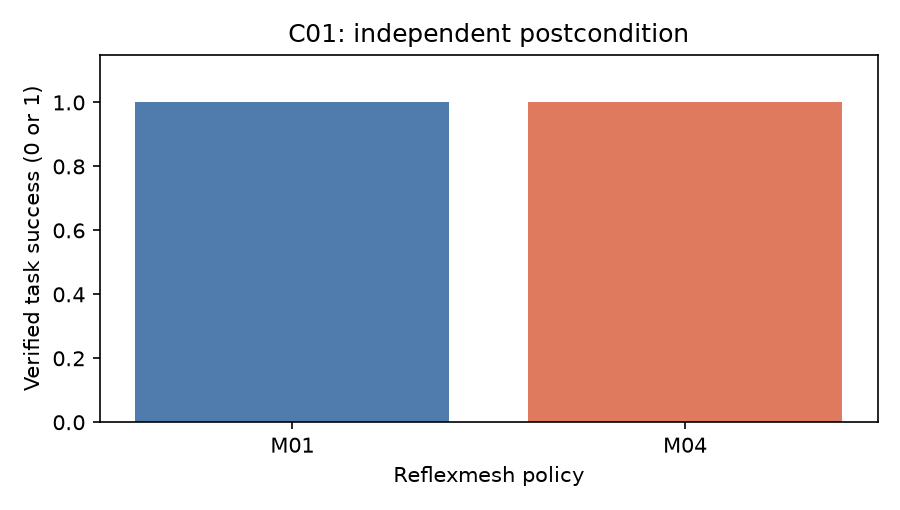

In [8]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Verified task success (0 or 1)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: independent postcondition")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


In the reproducibility check for evaluation and transfer on C01, for evaluation and transfer, these bars show fresh task-postcondition outcomes for M01 and M04 on C01, with success encoded as 1 and failure as 0. Read the case and seed before comparing them. In the reproducibility check for evaluation and transfer on C01, this controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks;

### evaluation and transfer · L2 | Recorded controller time

In the reproducibility check for evaluation and transfer on C01, the evaluation and transfer timing chart uses hash-verified frozen records for M01 and M04 on C01, not machine-dependent timings from fresh episodes. This level 2 evaluation and transfer view describes the recorded environment under its declared case, variant and seed.

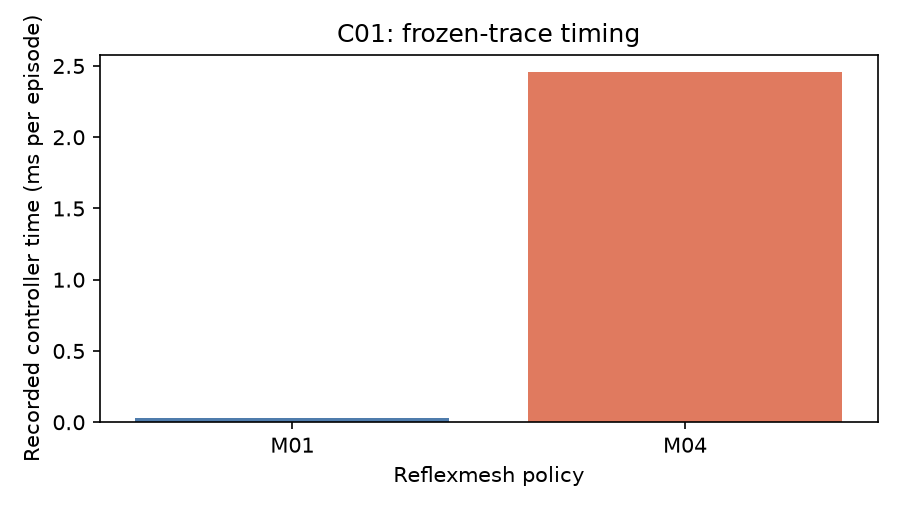

In [9]:
# Plot controller time from the hash-verified frozen records for the matched methods.
labels = list(fresh_runs)
latencies = [records[name]["metrics"]["controller_ms"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Recorded controller time (ms per episode)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: frozen-trace timing")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


The level 2 evaluation and transfer chart reads canonical M01/M04 records for C01, nominal variant and seed 40000 after the data boundary verifies their hashes. Within this evaluation and transfer rerun (C01), for this evaluation and transfer lesson, the stable figure describes recorded latency and intentionally makes no current-machine speed claim.

## Results

**Answer:** The evaluation and transfer comparison executes 2 fresh policy episodes, M01 and M04, under identical C01 conditions; keep the evaluation and transfer family and seed strata in view because the frozen matrix contains designed, not population-sampled, tasks.

The core matrix is saturated: In the reproducibility check for evaluation and transfer on C01, seven methods solve all 1,200 episodes and only 71/1,440 method/case/variant cells vary by seed; For the matched evaluation and transfer rerun on C01, in semantic transfer, M04 solves 24/24 structural cases while M12 solves 21/24; In the reproducibility check for evaluation and transfer on C01, the larger opaque semantic lane also favors M09 over M12; No learned-superiority claim is supported.

## Summary

For the matched evaluation and transfer rerun on C01, this evaluation and transfer example uses C01 to show behavior under one declared condition. For the matched evaluation and transfer rerun on C01, keep the measured outcome separate from claims about broader software-control intelligence.



## References
- [TOOLSANDBOX](https://arxiv.org/abs/2408.04682) - [SWE](https://arxiv.org/abs/2310.06770) - [TAU2](https://arxiv.org/abs/2506.07982)